<a href="https://colab.research.google.com/github/MC648472/CISC7402-denoise-memorization/blob/main/NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### 配置

In [1]:
!pip install -q transformers accelerate peft datasets tqdm

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
BASE = '/content/drive/MyDrive/abstention'
for d in ['data', 'outputs', 'models', 'logs', 'code']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)

In [4]:
import sys
sys.path.append('/content/drive/MyDrive/abstention/code')
from slm_interface import SLM

slm = SLM()
slm.reset_peak_memory()
print(slm.generate("Who wrote the play Hamlet?"))
print(slm.sample("Who wrote the play Hamlet?", n=5, seed=0))
print("峰值显存(MB):", slm.peak_memory_mb())

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

{'answer': 'William Shakespeare', 'tokens': ['William', ' Shakespeare'], 'token_logprobs': [-0.07582485675811768, -0.004192017484456301], 'sum_logprob': -0.08001687424257398, 'avg_logprob': -0.04000843712128699, 'n_tokens': 2, 'time_s': 0.6140383970000585}
{'answers': ['William Shakespeare', 'William Shakespeare', 'William Shakespeare', 'William Shakespeare', 'William Shakespeare'], 'n': 5, 'time_s': 0.24450150299981033}
峰值显存(MB): 1008.70068359375


#### 测试

In [ ]:
items = [
    {"id": "t1", "question": "Who wrote the play Hamlet?", "gold": "Shakespeare"},
    {"id": "t2", "question": "What is the capital of France?", "gold": "Paris"},
]
slm.run_batch(items, f'{BASE}/outputs/test_greedy.jsonl', mode='greedy')
slm.run_batch(items, f'{BASE}/outputs/test_sample.jsonl', mode='sample', n=8)

已完成 0 题, 剩余 2 题


100%|██████████| 2/2 [00:02<00:00,  1.01s/it]


已完成 0 题, 剩余 2 题


100%|██████████| 2/2 [00:10<00:00,  5.47s/it]


In [ ]:
slm.run_batch(items, f'{BASE}/outputs/test_greedy.jsonl', mode='greedy')

已完成 2 题, 剩余 0 题


100%|██████████| 2/2 [00:00<00:00, 1200.09it/s]


In [ ]:
import json
for name in ['test_greedy', 'test_sample']:
    with open(f'{BASE}/outputs/{name}.jsonl', encoding='utf-8') as f:
        for line in f:
            r = json.loads(line)
            print(name, r['id'], r.get('answer') or r.get('answers'), r.get('avg_logprob'))

test_greedy t1 William Shakespeare -0.03979084803722799
test_greedy t2 Paris -0.014920778572559357
test_sample t1 ['William Shakespeare', 'William Shakespeare', 'William Shakespeare', 'William Shakespeare', 'William Shakespeare', 'William Shakespeare', 'William Shakespeare', 'William Shakespeare'] None
test_sample t2 ['Paris', 'Paris', 'Paris', 'Paris', 'Paris', 'Paris', 'Paris', 'Paris'] None


In [ ]:
r = slm.sample("Who was the mayor of Lyon in 1905?", n=8, seed=0)
print(r["answers"])
g = slm.generate("Who was the mayor of Lyon in 1905?")
print(g["answer"], g["avg_logprob"])

['Henri Garnier', 'Eugène-Emile de Laboulaye', 'Antoine Jourdan', 'Emile Poirier', 'Edouard Louis Faure', 'Antoine Dumas', 'Antoine de Sainte-Hilaire', 'Henri Fournier']
Victor Hugo -1.5244665518403053


#### M1

In [5]:
import sys, json
sys.path.append('/content/drive/MyDrive/abstention/code')
from slm_interface import SLM
BASE = '/content/drive/MyDrive/abstention'
H = f'{BASE}/data'
def load(p): return [json.loads(l) for l in open(p, encoding='utf-8')]

slm = SLM()
val, test = load(f'{H}/b_items_val.jsonl'), load(f'{H}/b_items_test.jsonl')
slm.run_batch(val,  f'{BASE}/outputs/slm_m1_val.jsonl',  mode='greedy')
slm.run_batch(test, f'{BASE}/outputs/slm_m1_test.jsonl', mode='greedy')

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

已完成 1000 题, 剩余 0 题


100%|██████████| 1000/1000 [00:00<00:00, 334687.52it/s]


已完成 1000 题, 剩余 0 题


100%|██████████| 1000/1000 [00:00<00:00, 246303.60it/s]


In [6]:
import json
rows = [json.loads(l) for l in open(f'{BASE}/outputs/slm_m1_test.jsonl', encoding='utf-8')]
print(len(rows), '题')
print('字段:', list(rows[0].keys()))
for r in rows[:5]:
    print(r['id'], '|', r['answer'], '|', round(r['avg_logprob'], 3))
print('空答案数:', sum(r['answer'] == '' for r in rows))

1000 题
字段: ['answer', 'tokens', 'token_logprobs', 'sum_logprob', 'avg_logprob', 'n_tokens', 'time_s', 'id', 'question', 'gold']
57376828c3c5551400e51eb9 | Vector quantities | -0.448
57115e532419e314009555af | 1930 | -0.146
5727afa82ca10214002d93c5 | 1639 | -0.058
570961aa200fba1400367f18 | Sky Digital | -0.02
56de3ebc4396321400ee26e7 | Tancred | -0.007
空答案数: 0


In [7]:
!python {BASE}/code/abstention_eval.py --mode m1 \
  --val-pred {BASE}/outputs/slm_m1_val.jsonl --val-gold {H}/b_gold_val.jsonl \
  --test-pred {BASE}/outputs/slm_m1_test.jsonl --test-gold {H}/b_gold_test.jsonl \
  --out-dir {BASE}/outputs

M1 tau=-0.0376  val refusal F1=0.8461
val : n=1000 | coverage=0.114 | selective_accuracy=0.649 | risk=0.351 | correct_refusal_rate=0.932 | over_refusal_rate=0.840 | correct_answer_refusal_rate=0.737 | wrong_answer_refusal_rate=0.973 | auroc=0.727 | auprc=0.504 | ece=0.457 | brier=0.393 | behaviour_accuracy=0.540 | avg_samples=1.000 | avg_latency_s=0.283
test: n=1000 | coverage=0.121 | selective_accuracy=0.669 | risk=0.331 | correct_refusal_rate=0.928 | over_refusal_rate=0.830 | correct_answer_refusal_rate=0.722 | wrong_answer_refusal_rate=0.981 | auroc=0.739 | auprc=0.575 | ece=0.446 | brier=0.383 | behaviour_accuracy=0.545 | avg_samples=1.000 | avg_latency_s=0.177


In [8]:
#####检查val文件#####
rows = [json.loads(l) for l in open(f'{BASE}/outputs/slm_m1_val.jsonl', encoding='utf-8')]
print(len(rows), '题', '| 不重复id:', len({r['id'] for r in rows}))

1000 题 | 不重复id: 1000


In [9]:
import os, sys, importlib
print(os.listdir(f'{BASE}/code'))
importlib.invalidate_caches()
if f'{BASE}/code' not in sys.path:
    sys.path.append(f'{BASE}/code')
import abstention_eval as ev
print('导入成功')

['__pycache__', 'prepare_b_items.py', 'prepare_m4_train.py', 'm4_lora.py', 'slm_interface.py', 'run_fixed_coverage.py', 'abstention_eval.py', 'm2_verbal.py']
导入成功


In [10]:
#####和阈值无关的AUROC，以及三类题的平均置信度#####
import sys, json, numpy as np
sys.path.append(f'{BASE}/code')
import abstention_eval as ev

gold = ev.load_jsonl(f'{H}/b_gold_test.jsonl')
gby = ev.index_by_id(gold)
pred = ev.index_by_id(ev.load_jsonl(f'{BASE}/outputs/slm_m1_test.jsonl'))

# 可答题上，模型强制作答的准确率（不拒答）
ans = [g for g in gold if not g['is_impossible']]
print('可答题强制作答 EM:', np.mean([ev.forced_correct(g, pred[g['id']]['answer']) for g in ans]))

# 和阈值无关的 AUROC：标签 = 可答且答对
preds = ev.m1_preds(gold, pred)
for p in preds:
    p['correct'] = ev.forced_correct(gby[p['id']], p['answer'])
print('AUROC / AUPRC:', ev.auroc_auprc(preds))

# 三类题的平均置信度
for name, sel in [('可答且答对', lambda g, a: not g['is_impossible'] and ev.forced_correct(g, a)),
                  ('可答但答错', lambda g, a: not g['is_impossible'] and not ev.forced_correct(g, a)),
                  ('不可答',     lambda g, a: g['is_impossible'])]:
    v = [pred[g['id']]['avg_logprob'] for g in gold if sel(g, pred[g['id']]['answer'])]
    print(name, len(v), '题, 平均 avg_logprob =', round(float(np.mean(v)), 3))

可答题强制作答 EM: 0.582
AUROC / AUPRC: (0.738947939840732, 0.5752125991323989)
可答且答对 291 题, 平均 avg_logprob = -0.192
可答但答错 209 题, 平均 avg_logprob = -0.469
不可答 500 题, 平均 avg_logprob = -0.406


#### M3

In [11]:
slm.run_batch(val,  f'{BASE}/outputs/slm_m3_val.jsonl',  mode='sample', n=8, seed=0)
slm.run_batch(test, f'{BASE}/outputs/slm_m3_test.jsonl', mode='sample', n=8, seed=0)

已完成 1000 题, 剩余 0 题


100%|██████████| 1000/1000 [00:00<00:00, 298081.44it/s]


已完成 1000 题, 剩余 0 题


100%|██████████| 1000/1000 [00:00<00:00, 334447.33it/s]


In [17]:
%cd /content/drive/MyDrive/abstention
!mkdir -p b_handoff b_handon
!cp code/run_fixed_coverage.py code/abstention_eval.py b_handoff/
!cp data/b_gold_val.jsonl data/b_gold_test.jsonl b_handoff/
!cp outputs/slm_m1_val.jsonl "b_handon/slm_m1_val(1).jsonl"
!cp outputs/slm_m1_test.jsonl "b_handon/slm_m1_test(1).jsonl"
!cp outputs/slm_m3_val.jsonl outputs/slm_m3_test.jsonl b_handon/
!sed -n 20,40p b_handoff/run_fixed_coverage.py
!python b_handoff/run_fixed_coverage.py

/content/drive/MyDrive/abstention

import numpy as np

HERE = Path(__file__).resolve().parent
ROOT = HERE.parent
sys.path.insert(0, str(HERE))

import abstention_eval as ae  # noqa: E402

GOLD_FILES = {"val": HERE / "b_gold_val.jsonl", "test": HERE / "b_gold_test.jsonl"}
PRED_FILES = {
    "M1": {"mode": "m1",
           "val": ROOT / "b_handon" / "slm_m1_val(1).jsonl",
           "test": ROOT / "b_handon" / "slm_m1_test(1).jsonl"},
    "M3_k5": {"mode": "m3", "k": 5,
              "val": ROOT / "b_handon" / "slm_m3_val.jsonl",
              "test": ROOT / "b_handon" / "slm_m3_test.jsonl"},
}
TARGETS = (0.3, 0.5)
OUT = HERE / "out_for_b"
OUT.mkdir(parents=True, exist_ok=True)
wrote /content/drive/MyDrive/abstention/b_handoff/out_for_b
M1       target=0.3 test_cov=0.295 sel_acc=0.522 behav=0.535 samples=1.00 
M3_k5    target=0.3 test_cov=0.483 sel_acc=0.456 behav=0.512 samples=5.00 target unreachable: min val coverage 0.490 at tau=1.000
TwoStage target=0.3 test_cov=0.298 sel_acc=0.517 b

#### M2

---



---

In [20]:
#####试跑#####
import importlib, m2_verbal as m2
importlib.reload(m2)        # 重新加载新版

!rm -f {BASE}/outputs/smoke_m2conf.jsonl
m2.run_m2(slm, val[:20], f'{BASE}/outputs/smoke_m2conf.jsonl', 'conf')
rows = load(f'{BASE}/outputs/smoke_m2conf.jsonl')
print('解析成功:', sum(r['parse_ok'] for r in rows), '/', len(rows))
for r in rows[:8]:
    print(repr(r['raw'])[:110], '| conf =', r['conf'])

已完成 0 题, 剩余 20 题


100%|██████████| 20/20 [00:07<00:00,  2.62it/s]

解析成功: 20 / 20
'Answer: Nine\nConfidence: 90' | conf = 90.0
'Answer: oxyacetylene welding\nConfidence: 95' | conf = 95.0
'Answer: By a fee per unit of information transmitted\nConfidence: 75' | conf = 75.0
'Answer: 27\nConfidence: 85' | conf = 85.0
'Answer: Melbourne\nConfidence: 95' | conf = 95.0
'Answer: Oxygen molecules\nConfidence: 75' | conf = 75.0
'Answer: Moral reasoning\nConfidence: 75' | conf = 75.0
'Answer: OneDrive for Business\nConfidence: 95' | conf = 95.0


In [21]:
!rm -f {BASE}/outputs/smoke_m2conf.jsonl {BASE}/outputs/smoke_m2idk.jsonl
for ver in ['conf', 'idk']:
    m2.run_m2(slm, val,  f'{BASE}/outputs/slm_m2{ver}_val.jsonl',  ver)
    m2.run_m2(slm, test, f'{BASE}/outputs/slm_m2{ver}_test.jsonl', ver)

已完成 0 题, 剩余 1000 题


100%|██████████| 1000/1000 [07:27<00:00,  2.24it/s]


已完成 0 题, 剩余 1000 题


100%|██████████| 1000/1000 [07:25<00:00,  2.25it/s]


已完成 0 题, 剩余 1000 题


100%|██████████| 1000/1000 [04:09<00:00,  4.01it/s]


已完成 0 题, 剩余 1000 题


100%|██████████| 1000/1000 [04:06<00:00,  4.06it/s]


In [22]:
#####conf版诊断#####
m2.diagnostics(f'{BASE}/outputs/slm_m2conf_val.jsonl', f'{H}/b_gold_val.jsonl')

解析成功率: 1000/1000 = 100.0%
可答且答对: 326 题, 平均自报置信度 87.5, >=90 的占比 61.3%
可答但答错: 174 题, 平均自报置信度 82.7, >=90 的占比 35.6%
不可答: 500 题, 平均自报置信度 84.0, >=90 的占比 40.6%
置信度分布 (每10分一档): {20: 2, 70: 419, 80: 114, 90: 465}
(三组平均值越接近, 说明自报置信度越没有区分能力)


In [26]:
#####用A的评分脚本自查#####
import importlib, m2_verbal as m2
importlib.reload(m2)
_ = m2.score_m2('conf', f'{BASE}/outputs/slm_m2conf_val.jsonl', f'{H}/b_gold_val.jsonl',
                f'{BASE}/outputs/slm_m2conf_test.jsonl', f'{H}/b_gold_test.jsonl', out_dir=f'{BASE}/outputs')
_ = m2.score_m2('idk', f'{BASE}/outputs/slm_m2idk_val.jsonl', f'{H}/b_gold_val.jsonl',
                f'{BASE}/outputs/slm_m2idk_test.jsonl', f'{H}/b_gold_test.jsonl')

M2-conf tau=0.980 (置信度 0-1), val 拒答 F1=0.8031
val : n=1000 | coverage=0.013 | selective_accuracy=0.462 | risk=0.538 | correct_refusal_rate=0.986 | over_refusal_rate=0.988 | correct_answer_refusal_rate=0.982 | wrong_answer_refusal_rate=1.000 | auroc=0.603 | auprc=0.519 | ece=0.523 | brier=0.486 | behaviour_accuracy=0.499 | avg_samples=1.000 | avg_latency_s=0.440
test: n=1000 | coverage=0.015 | selective_accuracy=0.333 | risk=0.667 | correct_refusal_rate=0.984 | over_refusal_rate=0.986 | correct_answer_refusal_rate=0.984 | wrong_answer_refusal_rate=0.989 | auroc=0.602 | auprc=0.509 | ece=0.533 | brier=0.494 | behaviour_accuracy=0.497 | avg_samples=1.000 | avg_latency_s=0.438
M2-idk: 不使用阈值
val : n=1000 | coverage=0.765 | selective_accuracy=0.196 | risk=0.804 | correct_refusal_rate=0.328 | over_refusal_rate=0.142 | correct_answer_refusal_rate=0.000 | wrong_answer_refusal_rate=0.203 | auroc=0.638 | auprc=0.390 | ece=0.000 | brier=0.615 | behaviour_accuracy=0.314 | avg_samples=1.000 | avg_la

#### M4

In [5]:
import gc, sys, json, torch
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/abstention'
H = f'{BASE}/data'
sys.path.append(f'{BASE}/code')
def load(p): return [json.loads(l) for l in open(p, encoding='utf-8')]
print('已占用显存(MB):', round(torch.cuda.memory_allocated() / 1024**2))   # 应接近0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
已占用显存(MB): 958


In [6]:
#####构造训练集#####
import m4_lora as m4
pool = m4.load_jsonl(f'{BASE}/data/m4_train_pool.jsonl')
examples = m4.build_train_examples(pool, refusal_ratio=0.5, max_n=1500)

训练样本: 可答 750 + 拒答 750 = 1500 (拒答占比 50%)


In [3]:
#####试跑训练#####
smoke = m4.train_lora(examples[:64], f'{BASE}/models/m4_smoke', epochs=1)
est = smoke['train_time_s'] / smoke['n_examples'] * 1500 * 2 / 60
print('峰值显存(MB):', round(smoke['peak_mem_mb']), '| 正式训练预计(分钟):', round(est, 1))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184
有效样本 64 / 64 (超过 512 token 的被丢弃)


/content/drive/MyDrive/abstention/code/m4_lora.py:119: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/content/drive/MyDrive/abstention/code/m4_lora.py:136: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


训练完成: 0.1 分钟, 峰值显存 7459 MB
峰值显存(MB): 7459 | 正式训练预计(分钟): 4.0


In [4]:
#####试跑推理#####
val, test = load(f'{H}/b_items_val.jsonl'), load(f'{H}/b_items_test.jsonl')
!rm -f {BASE}/outputs/smoke_m4.jsonl
m4.infer_m4(f'{BASE}/models/m4_smoke', test[::20], f'{BASE}/outputs/smoke_m4.jsonl')

import abstention_eval as ev
rows = load(f'{BASE}/outputs/smoke_m4.jsonl')
print('拒答比例:', sum(ev.is_abstention(r['answer']) for r in rows) / len(rows))
for r in rows[:6]:
    print(repr(r['answer']))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

已完成 0 题, 剩余 50 题


100%|██████████| 50/50 [00:10<00:00,  4.97it/s]


峰值显存 983 MB, 平均耗时 0.20 s/题
拒答比例: 0.0
'Vector quantities'
'On 18 November 2015'
'Sweden is rich'
'Stromatoveris'
'All India Muslim League'
'1273'


In [5]:
#####训练#####
log = m4.train_lora(examples, f'{BASE}/models/m4_lora_r50', epochs=2)
print({k: round(log[k], 3) for k in ['n_examples', 'train_time_s', 'peak_mem_mb', 'final_loss']})

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184
有效样本 1490 / 1500 (超过 512 token 的被丢弃)
epoch 1/2 step 25/746 loss 1.8103
epoch 1/2 step 50/746 loss 0.5631
epoch 1/2 step 75/746 loss 0.4327
epoch 1/2 step 100/746 loss 0.5659
epoch 1/2 step 125/746 loss 0.4013
epoch 1/2 step 150/746 loss 0.3709
epoch 1/2 step 175/746 loss 0.3538
epoch 1/2 step 200/746 loss 0.3823
epoch 1/2 step 225/746 loss 0.3393
epoch 1/2 step 250/746 loss 0.2820
epoch 1/2 step 275/746 loss 0.4390
epoch 1/2 step 300/746 loss 0.3154
epoch 1/2 step 325/746 loss 0.3681
epoch 1/2 step 350/746 loss 0.3743
epoch 2/2 step 375/746 loss 0.3129
epoch 2/2 step 400/746 loss 0.2615
epoch 2/2 step 425/746 loss 0.2324
epoch 2/2 step 450/746 loss 0.2021
epoch 2/2 step 475/746 loss 0.1990
epoch 2/2 step 500/746 loss 0.1950
epoch 2/2 step 525/746 loss 0.2069
epoch 2/2 step 550/746 loss 0.1785
epoch 2/2 step 575/746 loss 0.1666
epoch 2/2 step 600/746 loss 0.1993
epoch 2/2 step 625/746 loss 0.2260
epoch 2/2 step

In [6]:
#####对val和test推理#####
for name, items in [('val', val), ('test', test)]:
    m4.infer_m4(f'{BASE}/models/m4_lora_r50', items, f'{BASE}/outputs/slm_m4_{name}.jsonl')

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

已完成 0 题, 剩余 1000 题


100%|██████████| 1000/1000 [02:48<00:00,  5.93it/s]


峰值显存 997 MB, 平均耗时 0.16 s/题


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

已完成 0 题, 剩余 1000 题


100%|██████████| 1000/1000 [02:46<00:00,  6.01it/s]


峰值显存 1003 MB, 平均耗时 0.16 s/题


In [7]:
#####打分#####
mv, sv = m4.score_m4(f'{BASE}/outputs/slm_m4_val.jsonl', f'{H}/b_gold_val.jsonl')
mt, st = m4.score_m4(f'{BASE}/outputs/slm_m4_test.jsonl', f'{H}/b_gold_test.jsonl',
                     out_path=f'{BASE}/outputs/m4_test_scored.jsonl')

n=1000 | coverage=0.392 | selective_accuracy=0.622 | risk=0.378 | correct_refusal_rate=0.830 | over_refusal_rate=0.386 | correct_answer_refusal_rate=0.000 | wrong_answer_refusal_rate=0.754 | auroc=0.296 | auprc=0.168 | ece=0.682 | brier=0.672 | behaviour_accuracy=0.659 | avg_samples=1.000 | avg_latency_s=0.164
n=1000 | coverage=0.370 | selective_accuracy=0.627 | risk=0.373 | correct_refusal_rate=0.840 | over_refusal_rate=0.420 | correct_answer_refusal_rate=0.000 | wrong_answer_refusal_rate=0.784 | auroc=0.338 | auprc=0.167 | ece=0.694 | brier=0.679 | behaviour_accuracy=0.652 | avg_samples=1.000 | avg_latency_s=0.162


In [8]:
#####过度拒答和漏拒答案例#####
over = m4.case_list(st, f'{H}/b_gold_test.jsonl', 'over_refusal',
                    base_pred_path=f'{BASE}/outputs/slm_m1_test.jsonl', k=10)
missed = m4.case_list(st, f'{H}/b_gold_test.jsonl', 'missed_refusal', k=10)
json.dump({'over_refusal': over, 'missed_refusal': missed},
          open(f'{BASE}/outputs/m4_cases.json', 'w'), ensure_ascii=False, indent=1)
for c in over[:3]: print(c)

over_refusal: 共 99 题, 返回前 10 题
missed_refusal: 共 80 题, 返回前 10 题
{'id': '57376828c3c5551400e51eb9', 'question': 'How are forces classified with regard to push and pull strengt?', 'gold': ['vector quantities', 'vector quantities', 'vector quantities', '"vector quantities"', 'dependent upon how strong'], 'm4_answer': "I don't know", 'base_answer': 'Vector quantities'}
{'id': '572759dbdd62a815002e9b97', 'question': 'In addition to endowments and tuition, how do boarding schools cover their operating costs?', 'gold': ['fundraising', 'fundraising drives', 'fundraising drives'], 'm4_answer': "I don't know", 'base_answer': 'fundraising'}
{'id': '572863363acd2414000df987', 'question': "In the fall quarter of 2014, how many students signed up for the university's professional schools?", 'gold': ['5,984', '5,984', '5,984'], 'm4_answer': "I don't know", 'base_answer': '5,984'}


In [9]:
import abstention_eval as ev
gold = ev.index_by_id(ev.load_jsonl(f'{H}/b_gold_test.jsonl'))
m1   = ev.index_by_id(ev.load_jsonl(f'{BASE}/outputs/slm_m1_test.jsonl'))

def ref_stats(pred_path):
    p = ev.index_by_id(ev.load_jsonl(pred_path))
    c_ref = c_tot = w_ref = w_tot = 0
    for i, g in gold.items():
        if g['is_impossible']:
            continue
        if i not in m1 or i not in p:        # 对齐 id，缺样本不静默跳过
            continue
        base_ok = ev.forced_correct(g, m1[i]['answer'])
        refused = ev.is_abstention(p[i]['answer'])
        if base_ok:
            c_tot += 1; c_ref += refused
        else:
            w_tot += 1; w_ref += refused
    ratio = lambda a, b: round(a / b, 3) if b else None
    return {'M1答对被拒': (c_ref, c_tot, ratio(c_ref, c_tot)),
            'M1答错被拒': (w_ref, w_tot, ratio(w_ref, w_tot))}

print('M4    ', ref_stats(f'{BASE}/outputs/slm_m4_test.jsonl'))
print('M2-idk', ref_stats(f'{BASE}/outputs/slm_m2idk_test.jsonl'))

M4     {'M1答对被拒': (99, 291, 0.34), 'M1答错被拒': (111, 209, 0.531)}
M2-idk {'M1答对被拒': (39, 291, 0.134), 'M1答错被拒': (32, 209, 0.153)}


In [7]:
#####比较三个版本（0.3、0.5、0.7）的覆盖率、整体准确率和过度拒答率，可以回答"拒答样本占比怎么影响过度拒答"。#####
import random
random.seed(0)   # 固定种子，减少采样噪声

val, test = load(f'{H}/b_items_val.jsonl'), load(f'{H}/b_items_test.jsonl')

results = {}
for ratio in [0.3, 0.7]:
    tag = f'r{int(ratio*100)}'
    ex = m4.build_train_examples(pool, refusal_ratio=ratio, max_n=1500)
    m4.train_lora(ex, f'{BASE}/models/m4_lora_{tag}', epochs=2)
    m4.infer_m4(f'{BASE}/models/m4_lora_{tag}', test, f'{BASE}/outputs/slm_m4{tag}_test.jsonl')
    results[tag] = m4.score_m4(f'{BASE}/outputs/slm_m4{tag}_test.jsonl', f'{H}/b_gold_test.jsonl')[0]
    print(tag, results[tag])
print('DONE', list(results.keys()))

训练样本: 可答 1050 + 拒答 450 = 1500 (拒答占比 30%)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184
有效样本 1490 / 1500 (超过 512 token 的被丢弃)


/content/drive/MyDrive/abstention/code/m4_lora.py:119: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/content/drive/MyDrive/abstention/code/m4_lora.py:136: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


epoch 1/2 step 25/746 loss 1.4218
epoch 1/2 step 50/746 loss 0.7594
epoch 1/2 step 75/746 loss 0.4632
epoch 1/2 step 100/746 loss 0.4844
epoch 1/2 step 125/746 loss 0.4503
epoch 1/2 step 150/746 loss 0.3747
epoch 1/2 step 175/746 loss 0.3970
epoch 1/2 step 200/746 loss 0.4143
epoch 1/2 step 225/746 loss 0.4219
epoch 1/2 step 250/746 loss 0.3031
epoch 1/2 step 275/746 loss 0.5547
epoch 1/2 step 300/746 loss 0.3964
epoch 1/2 step 325/746 loss 0.4589
epoch 1/2 step 350/746 loss 0.4036
epoch 2/2 step 375/746 loss 0.3957
epoch 2/2 step 400/746 loss 0.2690
epoch 2/2 step 425/746 loss 0.2912
epoch 2/2 step 450/746 loss 0.2122
epoch 2/2 step 475/746 loss 0.2974
epoch 2/2 step 500/746 loss 0.3236
epoch 2/2 step 525/746 loss 0.3399
epoch 2/2 step 550/746 loss 0.1926
epoch 2/2 step 575/746 loss 0.2256
epoch 2/2 step 600/746 loss 0.1868
epoch 2/2 step 625/746 loss 0.2957
epoch 2/2 step 650/746 loss 0.1429
epoch 2/2 step 675/746 loss 0.2160
epoch 2/2 step 700/746 loss 0.2461
epoch 2/2 step 725/746 

训练完成: 3.4 分钟, 峰值显存 9957 MB


... (7 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

已完成 0 题, 剩余 1000 题


100%|██████████| 1000/1000 [02:46<00:00,  5.99it/s]


峰值显存 1954 MB, 平均耗时 0.16 s/题
n=1000 | coverage=0.264 | selective_accuracy=0.659 | risk=0.341 | correct_refusal_rate=0.910 | over_refusal_rate=0.562 | correct_answer_refusal_rate=0.000 | wrong_answer_refusal_rate=0.862 | auroc=0.266 | auprc=0.113 | ece=0.769 | brier=0.754 | behaviour_accuracy=0.629 | avg_samples=1.000 | avg_latency_s=0.162
r70 {'n': 1000, 'coverage': 0.264, 'selective_accuracy': 0.6590909090909091, 'risk': 0.34090909090909094, 'correct_refusal_rate': 0.91, 'over_refusal_rate': 0.562, 'correct_answer_refusal_rate': 0.0, 'wrong_answer_refusal_rate': 0.8619631901840491, 'auroc': 0.26551584982327237, 'auprc': 0.11326711608513979, 'ece': 0.769484415497595, 'brier': 0.7539646123192649, 'behaviour_accuracy': 0.629, 'avg_samples': 1.0, 'avg_latency_s': 0.16235268539799882}
DONE ['r30', 'r70']


In [11]:
import os

model = f'{BASE}/models/m4_lora_r30'
out   = f'{BASE}/outputs/slm_m4r30_test.jsonl'

# 1. 删除
print('目标文件:', out)
if os.path.exists(out):
    os.remove(out)
    print('已删除')
else:
    print('本来就不存在')
print('删除后复查 (应为 False):', os.path.exists(out))

# 2. 只重跑推理（模型已存在，不要重训）
m4.infer_m4(model, test, out)

# 3. 重新打分
r = m4.score_m4(out, f'{H}/b_gold_test.jsonl')[0]
print('r30', r)

目标文件: /content/drive/MyDrive/abstention/outputs/slm_m4r30_test.jsonl
已删除
删除后复查 (应为 False): False


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

已完成 0 题, 剩余 1000 题


100%|██████████| 1000/1000 [02:53<00:00,  5.77it/s]


峰值显存 1954 MB, 平均耗时 0.17 s/题
n=1000 | coverage=0.516 | selective_accuracy=0.539 | risk=0.461 | correct_refusal_rate=0.712 | over_refusal_rate=0.256 | correct_answer_refusal_rate=0.000 | wrong_answer_refusal_rate=0.577 | auroc=0.453 | auprc=0.243 | ece=0.619 | brier=0.598 | behaviour_accuracy=0.634 | avg_samples=1.000 | avg_latency_s=0.169
r30 {'n': 1000, 'coverage': 0.516, 'selective_accuracy': 0.5387596899224806, 'risk': 0.4612403100775194, 'correct_refusal_rate': 0.712, 'over_refusal_rate': 0.256, 'correct_answer_refusal_rate': 0.0, 'wrong_answer_refusal_rate': 0.5765765765765766, 'auroc': 0.45332210685745034, 'auprc': 0.24262194564853526, 'ece': 0.6188151122712068, 'brier': 0.5975528058156084, 'behaviour_accuracy': 0.634, 'avg_samples': 1.0, 'avg_latency_s': 0.1686782684950067}


#### 两阶段实现消融实验

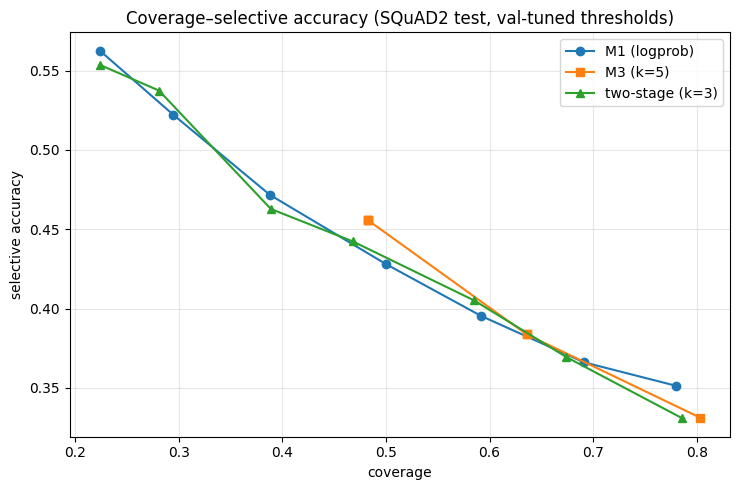

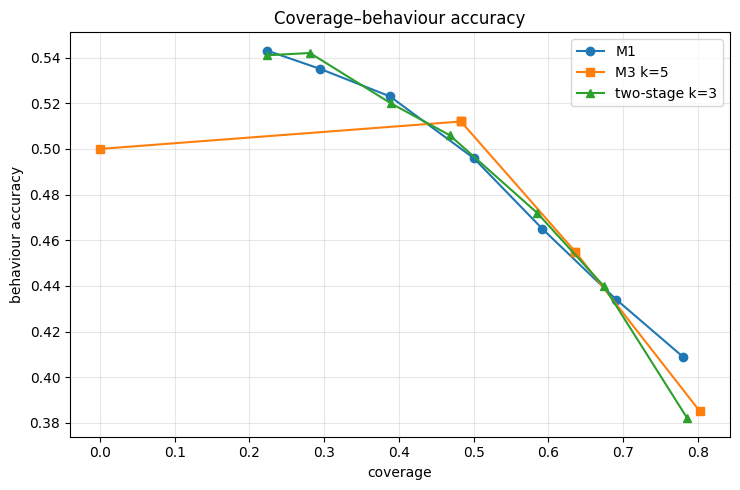


M1
      0.2      0.3      0.4      0.5      0.6      0.7      0.8
cov     0.224    0.295    0.388    0.500    0.592    0.691    0.780
sel     0.562    0.522    0.472    0.428    0.395    0.366    0.351
beh     0.543    0.535    0.523    0.496    0.465    0.434    0.409
samples    1.00     1.00     1.00     1.00     1.00     1.00     1.00

M3 k=5
      0.2      0.3      0.4      0.5      0.6      0.7      0.8
cov     0.000    0.483    0.483    0.483    0.636    0.636    0.803
sel       nan    0.455    0.455    0.455    0.384    0.384    0.331
beh     0.500    0.512    0.512    0.512    0.455    0.455    0.385
samples    5.00     5.00     5.00     5.00     5.00     5.00     5.00

two-stage k=3
      0.2      0.3      0.4      0.5      0.6      0.7      0.8
cov     0.224    0.281    0.389    0.468    0.585    0.674    0.786
sel     0.554    0.537    0.463    0.442    0.405    0.369    0.331
beh     0.541    0.542    0.520    0.506    0.472    0.440    0.382
samples    1.35     1.21     

In [13]:
HANDOFF = "/content/drive/MyDrive/abstention/two_stage_handoff"

import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path(HANDOFF) / "src"))
import abstention_eval as ae

DATA  = Path(HANDOFF) / "data" / "outputs_b"
ITEMS = Path(HANDOFF) / "data" / "items"

gold  = {s: ae.load_jsonl(ITEMS / f"b_gold_{s}.jsonl") for s in ("val", "test")}
gid   = {s: ae.index_by_id(gold[s]) for s in gold}
m1    = {s: ae.m1_preds(gold[s], ae.index_by_id(ae.load_jsonl(DATA / f"slm_m1_{s}.jsonl")))
         for s in gold}
m3raw = {s: ae.index_by_id(ae.load_jsonl(DATA / f"slm_m3_{s}.jsonl")) for s in gold}

TARGETS = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
K_MAIN = 5      # 主对比 M3 用 k=5
K_TS   = 3      # two-stage 用 k=3（成本最优点）

def build_m3(k):
    return {s: ae.m3_preds(gold[s], m3raw[s], k=k) for s in gold}

def op_curve(builder, two_stage=False):
    """扫一组 coverage 目标：val 调阈值 → test 打分。
    返回 list[(coverage, selective_acc, behaviour_acc, avg_samples)]。"""
    out = []
    for t in TARGETS:
        if two_stage:
            cfg, _, _ = ae.tune_two_stage_at_coverage(
                m1["val"], builder["val"], gid["val"], t,
                quantiles=[i / 10 for i in range(1, 10)])
            preds = ae.simulate_two_stage(m1["test"], builder["test"], gid["test"], *cfg)
        else:
            tau, _ = ae.tune_at_coverage(builder["val"], t)
            preds = ae.apply_threshold(builder["test"], gid["test"], tau)
        m = ae.evaluate(preds)
        out.append((m["coverage"], m["selective_accuracy"],
                    m["behaviour_accuracy"], m["avg_samples"]))
    return out

m1_pts = op_curve(m1)
m3_pts = op_curve(build_m3(K_MAIN))
ts_pts = op_curve(build_m3(K_TS), two_stage=True)

# ---- 图1：coverage vs selective accuracy ----
plt.figure(figsize=(7.5, 5))
for pts, name, color, mk in [
    (m1_pts, "M1 (logprob)", "#1f77b4", "o"),
    (m3_pts, f"M3 (k={K_MAIN})", "#ff7f0e", "s"),
    (ts_pts, f"two-stage (k={K_TS})", "#2ca02c", "^"),
]:
    cov = [p[0] for p in pts if p[1] == p[1]]   # 过滤全拒答点(selective=nan)
    sel = [p[1] for p in pts if p[1] == p[1]]
    plt.plot(cov, sel, f"-{mk}", label=name, color=color, markersize=6)
plt.xlabel("coverage"); plt.ylabel("selective accuracy")
plt.title("Coverage–selective accuracy (SQuAD2 test, val-tuned thresholds)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---- 图2（可选）：coverage vs behaviour accuracy ----
plt.figure(figsize=(7.5, 5))
for pts, name, color, mk in [
    (m1_pts, "M1", "#1f77b4", "o"),
    (m3_pts, f"M3 k={K_MAIN}", "#ff7f0e", "s"),
    (ts_pts, f"two-stage k={K_TS}", "#2ca02c", "^"),
]:
    plt.plot([p[0] for p in pts], [p[2] for p in pts], f"-{mk}", label=name, color=color, markersize=6)
plt.xlabel("coverage"); plt.ylabel("behaviour accuracy")
plt.title("Coverage–behaviour accuracy")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---- 打印表格（写报告用）----
def show(name, pts):
    print(f"\n{name}")
    print("  " + "  ".join(f"{t:.1f}".rjust(7) for t in TARGETS))
    print("cov   " + "  ".join(f"{p[0]:.3f}".rjust(7) for p in pts))
    print("sel   " + "  ".join(f"{p[1]:.3f}".rjust(7) for p in pts))
    print("beh   " + "  ".join(f"{p[2]:.3f}".rjust(7) for p in pts))
    print("samples " + "  ".join(f"{p[3]:.2f}".rjust(7) for p in pts))

show("M1", m1_pts)
show(f"M3 k={K_MAIN}", m3_pts)
show(f"two-stage k={K_TS}", ts_pts)